# 7.1 Как познакомиться с таблицей

Аналитика 101 · блок «Дата аналитика» · тема 07 «Разведочный анализ» · страница 7.1.

На примере выгрузки клиентов вы проверите структуру таблицы, построите карту пропусков, найдёте повторяющиеся идентификаторы и разберёте записи дат. Данные лежат в общем наборе `data/eda/`.

Для автоматического отчёта рядом есть отдельный скрипт `profile_report.py`. Использованной версии пакета нужен pandas 2. Команды установки и запуска приведены в начале скрипта.

**Как работать.** Выполняйте ячейки по порядку сверху вниз. Блоки самостоятельны: каждый читает файл заново.

Вывод получен на Python 3.13, pandas 3.0 и matplotlib 3.10.

## Где лежат данные

Код страницы читает файл по пути от корня папки с материалами: `data/eda/clients_export.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей. Туда же блок с картой пропусков сохранит `missing_map.csv` и `missing_map.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import pandas as pd

root = pathlib.Path.cwd()
while not (root / "data" / "eda").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/eda/
assert (root / "data" / "eda" / "clients_export.csv").exists(), \
    "Не найдена папка data/eda/. Скачайте общий набор темы 07 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.13 | pandas 3.0.5 | matplotlib 3.10.9


## Первые проверки выгрузки

### Как проверить структуру выгрузки в pandas

In [2]:
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")                           # 1. читаем как есть, без параметров
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e6:.2f} МБ")       # 2. размер таблицы и расход памяти
print(df.sample(2, random_state=7).T)                                     # 3. смотрим две случайные строки
num = df.select_dtypes("number")
passport = pd.DataFrame({"dtype": df.dtypes,                              # 4. тип, который определил pandas
                         "пропусков": df.isna().sum(),                    # 5. явные пропуски
                         "уникальных": df.nunique(),                      # 6. кардинальность
                         "min": num.min(), "max": num.max()},             # 7. диапазоны чисел
                        index=df.columns)
print(passport)
print("повторов client_id:", df["client_id"].dropna().duplicated().sum())  # 8. ключ уникален?
print(df["channel"].value_counts().to_dict())                              # 9. частоты всех значений канала
iso = pd.to_datetime(df["signup_date"], format="%Y-%m-%d", errors="coerce")
print("дат не в формате ГГГГ-ММ-ДД:", iso.isna().sum())                    # 10. формат дат

(12040, 10) 1.54 МБ
                              10028                      906  
client_id                  107816.0                   102101.0
signup_date              2025-10-09                 2025-08-21
last_order_at  2026-03-24T06:40:01Z  2026-02-15T15:13:47+03:00
country                          KZ                         BY
age                            18.0                       18.0
channel                    рассылка                    реклама
tier                              1                          2
visits_q1                        10                          6
orders_q1                       1.0                        2.0
spend_q1                     4380.0                     3210.0
                 dtype  пропусков  уникальных       min         max
client_id      float64         25       11975  100001.0    112000.0
signup_date        str          0         600       NaN         NaN
last_order_at      str       1718       10283       NaN         NaN
country        

## Карта пропусков

Один столбец исходной таблицы и группа из 301 строки образуют ячейку карты. Скрипт запишет доли пропусков в `missing_map.csv`, а график — в `missing_map.svg`. Следующая ячейка покажет этот график.

### Где отсутствует дата последнего заказа

In [3]:
import matplotlib
import numpy as np
import pandas as pd

matplotlib.use("Agg")                                     # рисуем в файл, без окна
import matplotlib.pyplot as plt

df = pd.read_csv("data/eda/clients_export.csv", na_values={"channel": ["-"]})  # «-» — тоже пропуск
df["age"] = df["age"].mask(df["age"] == 99)                              # 99 — «не указан»
df["orders_q1"] = df["orders_q1"].mask(df["orders_q1"] == -1)            # −1 — «неизвестно»
df = df.sort_values("orders_q1", na_position="first", kind="stable")     # сначала неизвестное число заказов, затем строки с нулём заказов

miss = df.isna()
bands = miss.groupby(np.arange(len(df)) // 301).mean()   # 40 полос по 301 строке: доля пропусков в полосе
bands.to_csv("missing_map.csv", index=False)
print("пропусков по столбцам:", miss.sum()[miss.sum() > 0].to_dict())
print((bands * 100).round().astype(int).iloc[[0, 1, 5, 6, 20, 39]].to_string())

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(bands, aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(df.columns)), df.columns, rotation=60, ha="right")
ax.set_ylabel("Группы по 301 строке в порядке возрастания orders_q1")
fig.savefig("missing_map.svg", bbox_inches="tight")

пропусков по столбцам: {'client_id': 25, 'last_order_at': 1718, 'country': 181, 'age': 360, 'channel': 120, 'orders_q1': 150}
    client_id  signup_date  last_order_at  country  age  channel  tier  visits_q1  orders_q1  spend_q1
0           0            0             59        1    2        1     0          0         50         0
1           0            0            100        2    3        1     0          0          0         0
5           0            0            100        0    3        1     0          0          0         0
6           0            0             12        2    3        1     0          0          0         0
20          0            0              0        2    3        1     0          0          0         0
39          0            0              0        2    4        0     0          0          0         0


График ниже построен по долям пропусков из missing_map.csv. Скрипт также сохраняет отдельный рисунок missing_map.svg.

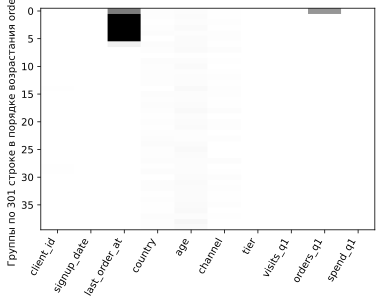

In [4]:
from IPython.display import SVG

SVG(filename="missing_map.svg")

## Коды пропусков, повторяющиеся номера и даты

### Какие коды пропусков распознал pandas

In [5]:
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")
raw = pd.read_csv("data/eda/clients_export.csv", dtype=str, keep_default_na=False)  # файл как текст, без списка пропусков
print("country: «N/A» в файле", (raw["country"] == "N/A").sum(), "→ NaN в pandas", df["country"].isna().sum())
print("channel: «-» в файле", (raw["channel"] == "-").sum(), "→ NaN в pandas", df["channel"].isna().sum())
print("orders_q1 = -1:", (df["orders_q1"] == -1).sum(), "  age = 99:", (df["age"] == 99).sum())

print(f"среднее orders_q1 {df['orders_q1'].mean():.3f}, без -1 {df['orders_q1'].replace(-1, None).mean():.3f}")
print(f"средний возраст {df['age'].mean():.1f}, без 99 {df['age'].replace(99, None).mean():.1f}")

fixed = pd.read_csv("data/eda/clients_export.csv", na_values={"channel": ["-"], "orders_q1": [-1], "age": [99]})
print(fixed[["channel", "orders_q1", "age"]].isna().sum().to_dict())

country: «N/A» в файле 181 → NaN в pandas 181
channel: «-» в файле 120 → NaN в pandas 0
orders_q1 = -1: 150   age = 99: 360
среднее orders_q1 2.018, без -1 2.056
средний возраст 38.3, без 99 36.4
{'channel': 120, 'orders_q1': 150, 'age': 360}


### Почему duplicated() отметил 64 строки вместо 40

In [6]:
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")
print("полных дублей строк:", df.duplicated().sum())
print("duplicated() по client_id:", df["client_id"].duplicated().sum())        # повторяющиеся пропуски тоже учитываются
key = df.dropna(subset=["client_id"])
print("повторов среди непустых id:", key["client_id"].duplicated().sum())

pairs = key[key["client_id"].duplicated(keep=False)].sort_values("client_id")
differ = pairs.groupby("client_id").nunique().gt(1).sum()
print("в скольких парах различается столбец:", differ[differ > 0].to_dict())
print(pairs[["client_id", "tier", "visits_q1", "orders_q1"]].head(4).to_string(index=False))

полных дублей строк: 0
duplicated() по client_id: 64
повторов среди непустых id: 40
в скольких парах различается столбец: {'visits_q1': 40}
 client_id  tier  visits_q1  orders_q1
  100176.0     3          8        3.0
  100176.0     3          9        3.0
  100192.0     1          6        2.0
  100192.0     1          7        2.0


### Как формат и смещение от UTC влияют на дату

In [7]:
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")
s = df["last_order_at"]
print("окончания строк:", s.str[19:].value_counts(dropna=False).to_dict())
try:
    pd.to_datetime(s)
except ValueError as e:
    print("ValueError:", e)

utc = pd.to_datetime(s, utc=True)                          # все моменты на одной шкале UTC
local = utc.dt.tz_convert("Europe/Moscow").dt.tz_localize(None)
cut = pd.to_datetime(s.str[:19])                            # ошибка: удалить смещение и считать все отметки местным временем
has = s.notna()                                             # NaT != NaT — сравниваем только заполненные
print("часы разошлись у", (local != cut)[has].sum(), "строк, дата — у", (local.dt.date != cut.dt.date)[has].sum())

d = df["signup_date"]                                       # два формата разбираем по отдельности
signup = pd.to_datetime(d, format="%Y-%m-%d", errors="coerce").fillna(
    pd.to_datetime(d, format="%d.%m.%Y", errors="coerce"))
print("signup_date:", signup.min().date(), "—", signup.max().date())
guess = pd.to_datetime(d, format="mixed", dayfirst=True)    # проверяем, как автоопределение трактует две записи даты
print("с format='mixed':", guess.min().date(), "—", guess.max().date())

окончания строк: {'+03:00': 8816, nan: 1718, 'Z': 1506}
ValueError: Mixed timezones detected. Pass utc=True in to_datetime or tz='UTC' in DatetimeIndex to convert to a common timezone.
часы разошлись у 1506 строк, дата — у 209
signup_date: 2025-06-01 — 2026-03-27


с format='mixed': 2025-01-06 — 2026-12-03


## Черновик автоматического отчёта

Этот блок страницы — в файле `profile_report.py` рядом с ноутбуком. Ему нужно отдельное окружение с pandas ниже 3.0; команды для установки и запуска записаны в начале файла.